# Question 1

In [233]:
import numpy as np
from dataclasses import dataclass, field
import os
from netCDF4 import Dataset
import matplotlib.pyplot as plt
from scipy.signal import detrend


In [7]:
@dataclass
class PierData:
    """A slice of the 2021 pier record. """
    dnum: np.ndarray          # times, as numpy datetime64[s]
    temperature: np.ndarray   # degrees C
    pressure: np.ndarray      # decibars
    readme: str = field(
        default='2021 Pier data, SIO221a, function get_2021_pier_data.py')

    def __len__(self):
        return len(self.dnum)

    
def get_pier_data(file, date_start=None, date_end=None):
    """Return temperature, pressure and time from the 2020 Scripps pier record.

    Parameters
    ----------
    date_start, date_end : numpy datetime64 or str, optional
        Bracket the period you want, e.g. '2020-06-04'.  Omit both to get the
        whole record.
    file : str, optional
        Path to the netCDF file.  Omit it and we find data/scripps_pier-2020.nc
        inside the class repo.

    Returns
    -------
    pier : PierData
    """

    nc = Dataset(file)
    try:
        time = np.asarray(nc.variables['time'][:])
        temperature = np.asarray(nc.variables['temperature'][:])
        pressure = np.asarray(nc.variables['pressure'][:])
    finally:
        nc.close()

    # netCDF time is seconds since 1970-01-01, which is exactly datetime64[s].
    dnum = time.astype('datetime64[s]')

    if date_start is None:
        i1 = np.ones(dnum.shape, dtype=bool)
    else:
        i1 = ((dnum > np.datetime64(date_start)) &
              (dnum < np.datetime64(date_end)))

    return PierData(dnum=dnum[i1],
                    temperature=temperature[i1],
                    pressure=pressure[i1])


def getManyPier(numyears, start, date_start=None, date_end=None):
    """
    converts from pier object to dictionary in order to append more easily

    takes in number of years to add together, starting year

    returns: PierData object 
    
    """
    pier_data = {"dnum":np.array([], dtype='datetime64[s]'), "temperature":np.array([]), "pressure":np.array([])} #make an initial dictionary to append all the data to
    for i in range(start,start+numyears):
        pier = get_pier_data(file= "../pier_data/scripps_pier-"+str(i)+".nc")
        pier_data["dnum"] = np.concatenate((pier_data["dnum"], pier.dnum)) #preserve the order, append new values to the end
        pier_data["temperature"] = np.concatenate((pier_data["temperature"], pier.temperature))
        pier_data["pressure"] = np.concatenate((pier_data["pressure"], pier.pressure))
    pier = PierData(dnum= pier_data["dnum"], temperature=pier_data["temperature"], pressure=pier_data["pressure"])
    return pier

In [8]:
pier = get_pier_data("../pier_data/scripps_pier-2021.nc")

In [22]:
pres = pier.pressure[70521:88190]
dates = pier.dnum[70521:88190]

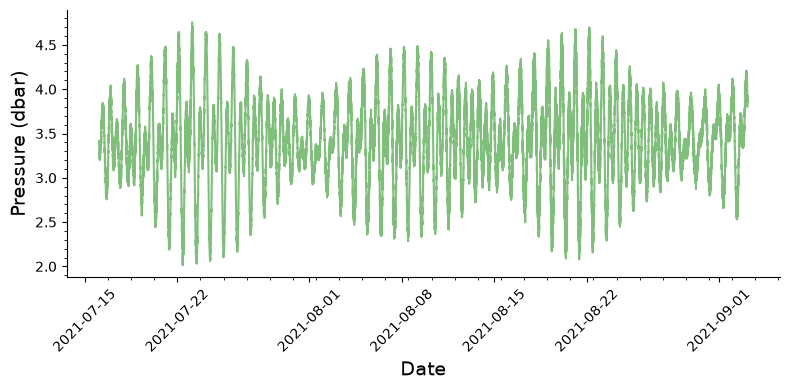

In [227]:
fig, ax = plt.subplots(figsize = (8,4))
ax.plot(dates, pres, color = "#7fbf7b")
ax.set_xlabel("Date", fontsize = 14)
ax.minorticks_on()
ax.set_ylabel("Pressure (dbar)", fontsize = 14)
ax.tick_params(axis='x', labelrotation=45)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [24]:
diffs = np.diff(dates)

In [25]:
np.where(diffs != 240)

(array([ 2418,  4950,  7494, 15040]),)

In [29]:
dates[2418:2422]

array(['2021-07-22T19:10:18', '2021-07-22T19:18:18',
       '2021-07-22T19:22:18', '2021-07-22T19:26:18'],
      dtype='datetime64[s]')

We need to add one data point in between 2418 and 2419.

In [30]:
dates[4950:4953]

array(['2021-07-29T20:02:18', '2021-07-29T20:10:18',
       '2021-07-29T20:14:18'], dtype='datetime64[s]')

We need to add one data point between 4950 and 4951.

In [31]:
dates[7494:7497]

array(['2021-08-05T21:42:18', '2021-08-05T21:50:18',
       '2021-08-05T21:54:18'], dtype='datetime64[s]')

We need to add one data point between 7494 and 7495.

In [32]:
dates[15040:15043]

array(['2021-08-26T20:50:18', '2021-08-26T20:58:18',
       '2021-08-26T21:02:18'], dtype='datetime64[s]')

We need to add one data point between 15040 and 15041.

In [ ]:
updates = np.insert(dates, 15041, '2021-08-26T20:54:18')
updates = np.insert(updates, 7495, '2021-08-05T21:46:18')
updates = np.insert(updates, 4951, '2021-07-29T20:06:18')
updates = np.insert(updates, 2419, '2021-07-22T19:14:18')

To update the pressures, we simply average between the existing values.

In [57]:
newpres = np.insert(pres, 15041, np.mean(pres[15040:15042]))
newpres = np.insert(newpres, 7495, np.mean(pres[7494:7496]))
newpres = np.insert(newpres, 4951, np.mean(pres[4950:4952]))
newpres = np.insert(newpres, 2419, np.mean(pres[2418:2420]))

In [61]:
updates[0],updates[-1]

(np.datetime64('2021-07-16T01:58:18'), np.datetime64('2021-09-03T04:06:18'))

The time record of interest goes from July 16th to September 3rd. The increment between the measurements is 240 seconds, or 4 minutes.

# Question 2

In [93]:
def getCoef(time, pres):
    arr_range = np.arange(0, len(time)*4, 4, dtype = float)
  
    A2 = np.column_stack([np.ones_like(time, dtype=float), arr_range,
    np.sin(2*np.pi*arr_range/(25.82*60)), np.cos(2*np.pi*arr_range/(25.82*60)), np.sin(2*np.pi*arr_range/(23.93*60)), np.cos(2*np.pi*arr_range/(23.93*60)), np.sin(2*np.pi*arr_range/(12.42*60)), np.cos(2*np.pi*arr_range/(12.42*60))])

    x, *_ = np.linalg.lstsq(A2, pres.astype(float), rcond=None)
    fit_2 = A2 @ x

    amp1 = np.sqrt(x[2]**2+x[3]**2)
    amp2 = np.sqrt(x[4]**2+x[5]**2)
    amp3 = np.sqrt(x[6]**2+x[7]**2)
    coefs = [x[0], x[1], amp1, amp2, amp3]
    return coefs, fit_2

In [87]:
def getCoef(time, pres):
    arr_range = np.arange(0, len(time)*4, 4,  dtype = float)
  
    A2 = np.column_stack([np.ones_like(time, dtype=float), arr_range,
    np.sin(2*np.pi*arr_range/(25.82*60), np.cos(2*np.pi*arr_range/(25.82*60)))])

    x, *_ = np.linalg.lstsq(A2, pres.astype(float), rcond=None)
    fit_2 = A2 @ x

    #amp1 = np.sqrt(x[2]**2+x[3]**2)
    #amp2 = np.sqrt(x[4]**2+x[5]**2)
    #amp3 = np.sqrt(x[6]**2+x[7]**2)
    #coefs = [x[0], x[1], amp1]
    return fit_2

In [94]:
coef, fit = getCoef(updates, newpres)

In [ ]:
newpres.astype(float)


np.float32(4.757)

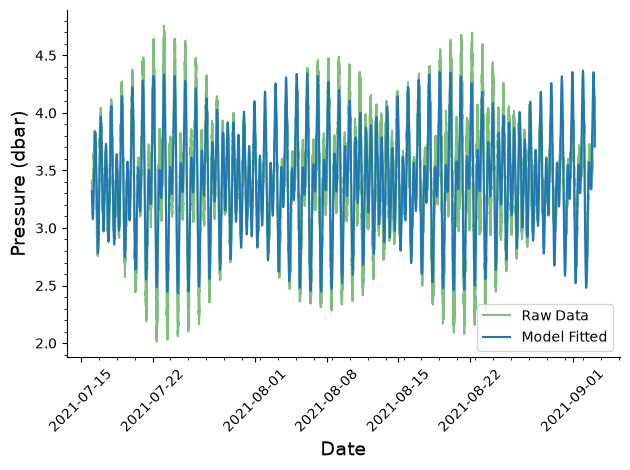

In [222]:
fig, ax = plt.subplots()
ax.plot(updates, newpres, color = "#7fbf7b", label = "Raw Data")
ax.plot(updates, fit, color = "#1f78b4", label = "Model Fitted")
ax.set_xlabel("Date", fontsize = 14)
ax.minorticks_on()
ax.set_ylabel("Pressure (dbar)", fontsize = 14)
ax.tick_params(axis='x', labelrotation=45)
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [96]:
coef

[np.float64(3.38699231363898),
 np.float64(6.398321398360019e-07),
 np.float64(0.23324088242092997),
 np.float64(0.366017358331049),
 np.float64(0.48323168477355916)]

The mean is 3.38 dbar. The O1 amplitude is 0.233 dbar, the K1 amplitude is 0.366 dbar, and the M2 amplitude is 0.483 dbar.

# Question 3

## Part a

N = 17673, df = 0.0204 cpd, Nyquist = 180.00 cpd
smallest |f| on the grid = 0.000e+00 (should be exactly↪0)
agrees with np.fft.fftshift(np.fft.fftfreq(N, dt)): True


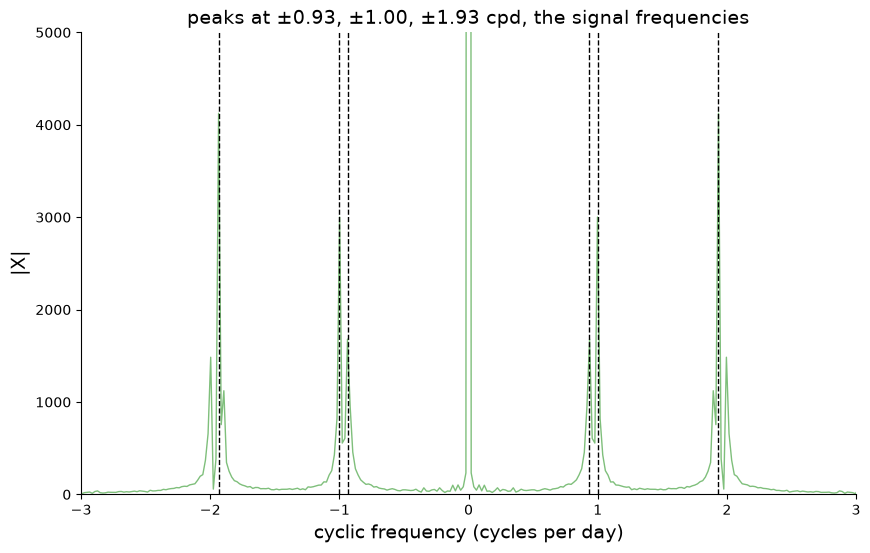

In [221]:
X = np.fft.fft(newpres)
dt = 0.00277777777
N = len(newpres)
T = dt*N
df = 1/T
fn = 1/2/dt # the Nyquist frequency
P = 1.07583333333
P2 = 0.99708333333
P3 = 0.5175
# Build the (shifted) frequency axis from the sample indices. This is correct
# for both even and odd N; zero frequency lands exactly on the grid.
k = np.arange(-(N//2), (N-1)//2 + 1)
f = k*df
print(f'N = {N}, df = {df:.4f} cpd, Nyquist = {fn:.2f} cpd')
print(f'smallest |f| on the grid = {np.min(np.abs(f)):.3e} (should be exactly↪0)')
# numpy has a helper that does exactly this - use it in real work:
print(f'agrees with np.fft.fftshift(np.fft.fftfreq(N, dt)): '
f'{np.allclose(f, np.fft.fftshift(np.fft.fftfreq(N, dt)))}')
# numpy puts zero frequency first, so shift to put it in the middle.
Xs = np.fft.fftshift(X)
fig, ax = plt.subplots(figsize = (10,6))
ax.plot(f, np.abs(Xs), lw=1, color = "#7fbf7b")
ax.set_xlabel('cyclic frequency (cycles per day)', fontsize=14)
ax.set_ylabel('|X|', fontsize=14)
ax.set_ybound(0,5000)
ax.set_xbound(-3,3)
for v in (1/P, -1/P):
    ax.axvline(v, color='k', ls='--', lw=1)
for v in (1/P2, -1/P2):
    ax.axvline(v, color='k', ls='--', lw=1)
for v in (1/P3, -1/P3):
    ax.axvline(v, color='k', ls='--', lw=1)
ax.set_title(fr'peaks at $\pm${(1/P):.2f}, $\pm${(1/P2):.2f}, $\pm${(1/P3):.2f} cpd, the signal frequencies', fontsize=14)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## Part b

In [188]:
lis = np.where(abs(X)>=1500)
lis

(array([    0,    46,    49,    95, 17578, 17624, 17627]),)

In [157]:
for i in lis:
    print(f[lis])

[-1.93515533 -0.99813275 -0.93702258  0.          0.93702258  0.99813275
  1.93515533]


When finding the peaks, the frequencies that correspond to the three highest peaks are: 1.93 cpd, 1.00 cpd, and 0.94 cpd. These are exactly the values of the frequencies corresponding to the tidal frequencies.

In [161]:
mean = X[0]/len(newpres)
mean

np.complex64(3.4119055+0j)

The mean pressure is 3.41 dbar.

In [194]:
lis = np.where(abs(X)>=1500)
lis = lis[0][4:]
amps = np.array([x for x in X[lis]])
amps = (2*np.abs(amps))/(len(newpres))
amps


array([0.46674117, 0.33970535, 0.19016543], dtype=float32)

The O1 amplitude is 0.190 dbar, the K1 amplitude is 0.366 dbar, and the M2 amplitude is 0.483 dbar in the Fourier analysis. 

## Part C

In [197]:
O1 = abs(amps[2]-0.23324088242092997)
K1 = abs(amps[1]-0.366017358331049)
M2 = abs(amps[0]- 0.48323168477355916)
O1, K1, M2

(np.float32(0.043075457), np.float32(0.026312023), np.float32(0.016490519))

The O1 amplitude is 0.233 dbar, the K1 amplitude is 0.366 dbar, and the M2 amplitude is 0.483 dbar in the least squares. We can find the difference between the two values (least squares and Fourier analysis). The difference between the values, listed as above, are 0.04, 0.03, and 0.02.

## Part D

In [240]:
data = detrend(newpres) # removes the mean at the same time
print(f'mean after detrending: {np.mean(data):.3e} m/s')
a = np.fft.fft(data)

mean after detrending: 1.377e-07 m/s


In [243]:
nf = np.arange(0, fn + df/2, df) 
amp = np.abs(a[:N//2 + 1])**2
amp = amp / N**2 # 1. the fft normalization
amp[1:-1] = amp[1:-1]*2 
amp = amp / df 

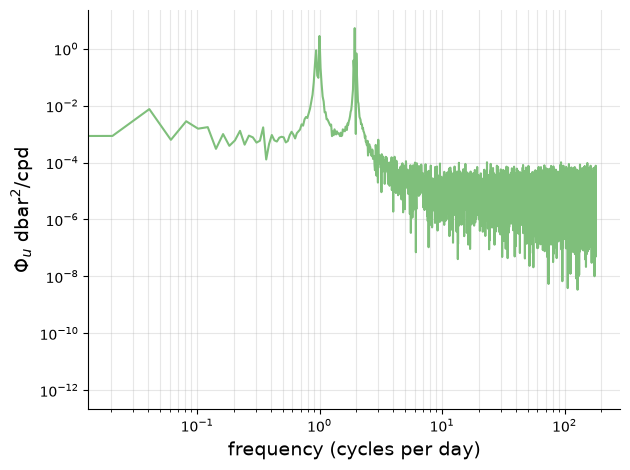

In [244]:
fig, ax = plt.subplots()
ax.loglog(nf, amp, color = "#7fbf7b")
ax.grid(True, which='both', alpha=0.3)
ax.set_ylabel(r'$\Phi_u$ dbar$^2$/cpd', fontsize=14)
ax.set_xlabel('frequency (cycles per day)', fontsize=14)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

The spectrum looks a bit flat, but has a somewhat downward trend. This leads me to believe that the spectrum is red.